# Lab 1.3 · LLM architecture

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

A decoder-only language model takes token IDs and produces next-token scores. An **embedding** is a lookup table with one vector per vocabulary entry. Each token gets its own row in the sequence, even when the same ID occurs twice. A position signal gives the model information about where each token appears. The toy position signal simply adds an index to a feature. Implementations such as rotary position embeddings instead inject position information inside attention.

The transformer stack updates those vectors while preserving the hidden width at its boundaries. A final projection, often called the **language model head**, gives each row one score per vocabulary entry. These raw scores are **logits**. During generation, the last row supplies the scores for the next token.

For two tokens, a hidden width of three, and a vocabulary size of five, the embedding output is `(2, 3)` and the head projection is `(2, 3) @ (3, 5) → (2, 5)`. Taking the final row leaves five candidate scores. The notebook uses deterministic row-wise placeholder blocks so you can focus on these interfaces. Real transformer blocks can mix information across positions through attention.

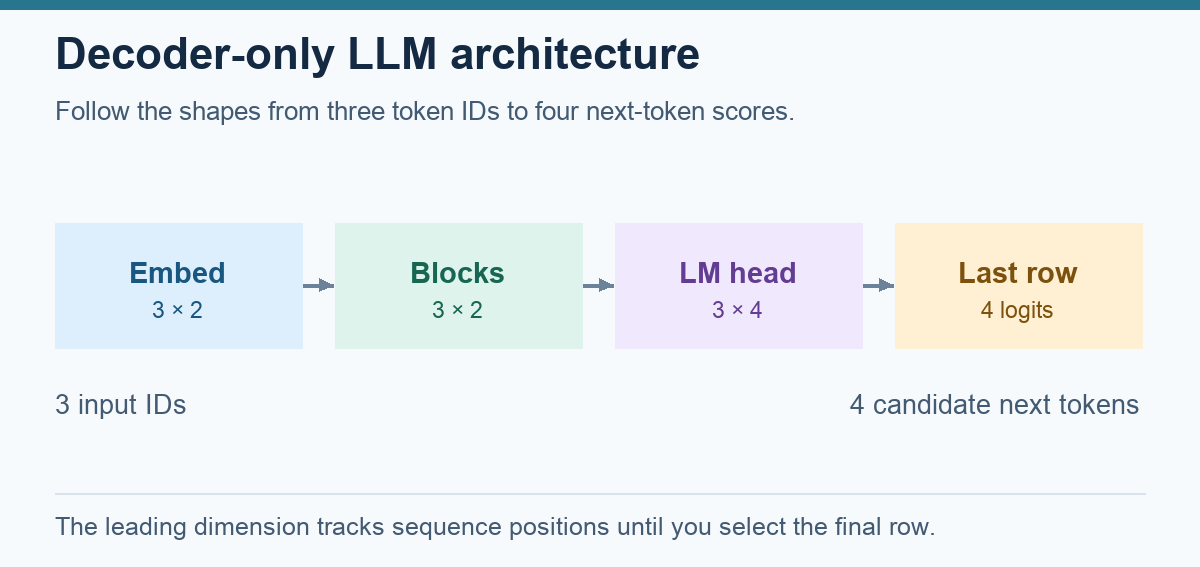

## Exercise map

1. **Build the input vectors** — Look up one vector per token ID and apply the supplied position convention to its first feature.
2. **Project hidden states to logits** — Complete the vocabulary projection, trace the shape after each block, and use the final logits row to choose a token.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
vocabulary = ["red", "blue", "green", "yellow"]
embeddings = [[1, 0], [0, 1], [1, 1], [-1, 0]]
head = [[1, 0, 1, -1], [0, 1, 1, 0]]
ids = [1, 0, 3]

def block_one(rows):
    return [[x + y, y] for x, y in rows]

def block_two(rows):
    return [[x, y - x] for x, y in rows]

def shape(rows):
    return (len(rows), len(rows[0]))

## Exercise 1. Build the input vectors

Look up each token's embedding and add its zero-based position to the first coordinate. Predict the shape before running the check. This position signal is deliberately simple.

**Implementation hint** — Use enumerate to get the position and token ID. Construct a new row instead of changing the shared embedding in place.

**After running the check** — Check both the shape and the values. The embedding table should still contain its original vectors after the lookup.

In [ ]:
def embed(token_ids):
    return None

In [ ]:
hidden = embed(ids)
if hidden is not None:
    assert hidden == [[0, 1], [2, 0], [1, 0]]
    assert embeddings[0] == [1, 0]
    print("PASS — embeddings", shape(hidden), hidden)

## Exercise 2. Project hidden states to logits

Use the head matrix to project each hidden row to four logits. Then run the supplied pipeline. Predict which dimension of the logits changes when you add a token.

**Implementation hint** — Use the same matrix indexing as Lab 1.1. For vocabulary entry j, multiply the hidden row by column j of the head.

**After running the check** — When you append a token, the number of rows changes. The number of candidate scores per row stays tied to the vocabulary.

In [ ]:
def project(rows):
    return None

In [ ]:
check_passed = False
if hidden is not None:
    after_one = block_one(hidden)
    after_two = block_two(after_one)
    logits = project(after_two)
    if logits is not None:
        assert logits == [[1, 0, 1, -1], [2, -2, 0, -2], [1, -1, 0, -1]]
        assert shape(project(block_two(block_one(embed(ids + [2]))))) == (4, 4)
        next_id = max(range(len(vocabulary)), key=logits[-1].__getitem__)
        print("Blocks:", shape(after_one), shape(after_two), "Logits:", shape(logits))
        print("PASS — next token:", vocabulary[next_id])
        check_passed = True
if not check_passed:
    print("Complete embed and project and rerun the checks in order.")

## Optional extension · Reading a model configuration

Kiely uses the model configuration to connect architectural choices to runtime support. Hidden width and vocabulary size set the dimensions used in this lab. The number of blocks tells you how many times a hidden state passes through the block interface.

Change only the vocabulary size in the toy configuration. Predict which matrix shapes change, then vary the number of layers and compare again.

**Reading** · Philip Kiely, *Inference Engineering*, §§2.2.1–2.2.2, pp. 49–50.

In [ ]:
def describe(config, sequence_length):
    vocab, width, layers = (config[key] for key in
                           ("vocab_size", "hidden_size", "num_hidden_layers"))
    return {"embedding": (vocab, width), "block output": (sequence_length, width),
            "block calls": layers, "logits": (sequence_length, vocab)}

config = {"vocab_size": 4, "hidden_size": 2, "num_hidden_layers": 2}
print(describe(config, 3))
expanded = describe(dict(config, vocab_size=8), 3)
assert expanded["logits"] == (3, 8) and expanded["block output"] == (3, 2)
print(expanded)
print(describe(dict(config, num_hidden_layers=4), 3))

## Wrap-up

Change the last token ID and inspect the logits. Which shapes stayed fixed? Why would a decoder use the last row to choose the next token?